In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [12]:
data = pd.read_csv(r'C:\Users\User1\OneDrive\Desktop\Python\retail_sales_dataset.csv')
print("Shape:",data.shape)
data.head()

Shape: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [14]:
print("Columns:")
print(data.columns.tolist())
print("\nData Types:")
print(data.dtypes)
print("\nMissing:")
print(data.isnull().sum())
print("\nDuplicates:", data.duplicated().sum())


Columns:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Data Types:
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

Missing:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicates: 0


In [17]:
 #Fix Date 
data['Date'] = pd.to_datetime(data['Date'])

# Basic numbers
print("Total Revenue:", data['Total Amount'].sum())
print("Average Sale:", round(data['Total Amount'].mean(), 2))
print("Total Transactions:", len(data))
print("Unique Customers:", data['Customer ID'].nunique())
print("\n", data.describe())

Total Revenue: 456000
Average Sale: 456.0
Total Transactions: 1000
Unique Customers: 1000

        Transaction ID                           Date         Age     Quantity  \
count     1000.000000                           1000  1000.00000  1000.000000   
mean       500.500000  2023-07-03 00:25:55.200000256    41.39200     2.514000   
min          1.000000            2023-01-01 00:00:00    18.00000     1.000000   
25%        250.750000            2023-04-08 00:00:00    29.00000     1.000000   
50%        500.500000            2023-06-29 12:00:00    42.00000     3.000000   
75%        750.250000            2023-10-04 00:00:00    53.00000     4.000000   
max       1000.000000            2024-01-01 00:00:00    64.00000     4.000000   
std        288.819436                            NaN    13.68143     1.132734   

       Price per Unit  Total Amount  
count     1000.000000   1000.000000  
mean       179.890000    456.000000  
min         25.000000     25.000000  
25%         30.000000     

Dataset has 1000 transactions from 1000 unique customers in 2023, total revenue 456,000 with average sale of 456. Distribution is skewed-median sale is 135, meaning most sales are small with a few large sales

                  count     sum        mean
Product Category                           
Electronics         342  156905  458.786550
Clothing            351  155580  443.247863
Beauty              307  143515  467.475570


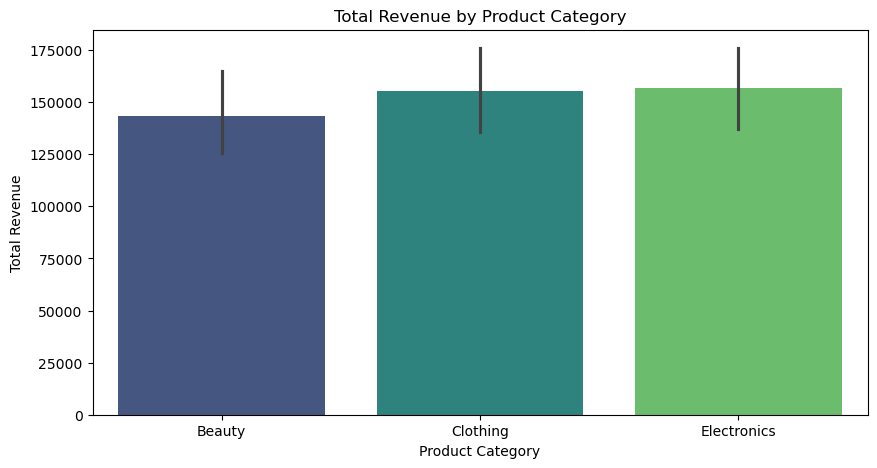

In [19]:
# By Category - Count and Revenue
print(data.groupby('Product Category')['Total Amount'].agg(['count','sum','mean']).sort_values('sum',ascending=False)) 

plt.figure(figsize=(10,5))
sns.barplot(data=data, x='Product Category', y='Total Amount', estimator='sum', palette='viridis')
plt.title('Total Revenue by Product Category')
plt.ylabel('Total Revenue')
plt.show()

Revenue is evenly balanced across categories. Electronics leads in total revenue(156,905), Clothing leads in volume (351 transactions), but Beauty has the highest average transaction value(467,48), suggesting higher-value baskets or premium pricing.

        count     sum        mean
Gender                           
Female    510  232840  456.549020
Male      490  223160  455.428571


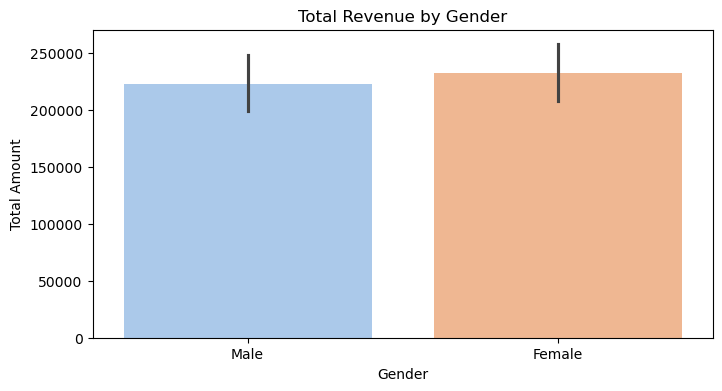

In [21]:
print(data.groupby('Gender')['Total Amount'].agg(['count','sum','mean']))

plt.figure(figsize=(8,4))
sns.barplot(data=data, x='Gender', y='Total Amount', estimator='sum', palette='pastel')
plt.title('Total Revenue by Gender')
plt.show()

Gender has no meaningful impact on spending. Female customers generate slightly more toala revenue(232,840 vs 223,160) due to slightly higher transcation count(519 vs 490), but average transaction value is virtually identical(456.55 vs 455.43). Marketing should not split by gender based on spending behaviour.

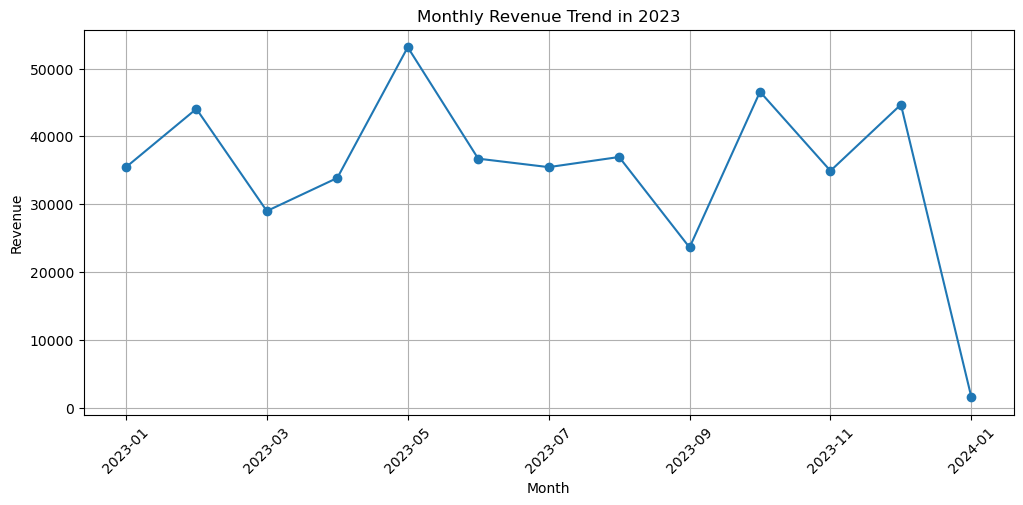

Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Name: Total Amount, dtype: int64


In [23]:
data['Month'] = data['Date'].dt.to_period('M').astype(str)

monthly = data.groupby('Month')['Total Amount'].sum()

plt.figure(figsize=(12,5))
monthly.plot(kind='line', marker='o')
plt.title('Monthly Revenue Trend in 2023')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()
print(monthly)

Monthly revenue is volatile with no clear growth trend. Peak in May(53,150), lowest full month in September(23,629).Jan 2024 is excluded because it's only 1 day of data.

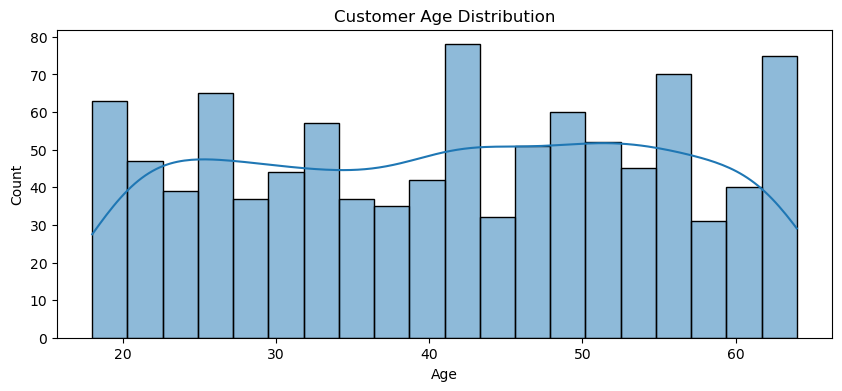

In [28]:
#Age distribution
plt.figure(figsize=(10,4))
sns.histplot(data['Age'], bins=20, kde=True)
plt.title('Customer Age Distribution')
plt.show()

There in no dominant age group. This store appeals equally to 20 year olds and 60 year olds. Age distribution is uniform (18-64). No specific age segment dominates, so age-based targeting is not useful.

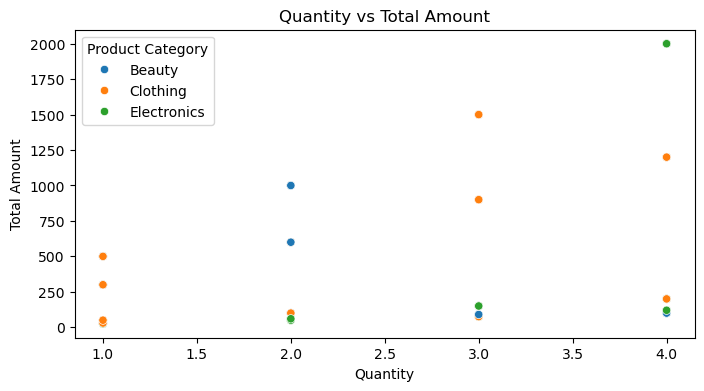

In [30]:
#Quantity vs Total Amount
plt.figure(figsize=(8,4))
sns.scatterplot(data=data, x='Quantity', y='Total Amount', hue='Product Category')
plt.title('Quantity vs Total Amount')
plt.show()

Quantity alone does not predict revenue. Price per Unit is the driver. A single high priced item can be worth more than 4 low priced items.

## Conclusion & Recommendations

1. **Revenue is balanced:** No single category dominates. Don't drop any category
2. **Beauty is the opportunity:** Highest average sale (467.48) despite fewest transactions. Promote Beauty to increase Basket size.
3. **Gender doesn't matter:** Spend per visit is identical. Don't waste budget on gender-specific campaigns.
4. **Focus on May retention:**  May was peak(53,150). Replicate May promotions. With 1000 customers buying only once, the biggest opportunity is getting customers to buy a 2nd time.
5. **Investigate September dip:** Lowest month(23,620)- was it stock, pricing,  or seasonality?
6. **Age is uniform:** Customers are evenly spread 18-64, no age group dominates. Don't target by age.
7. **Price beats quantity:** Total Amount is driven by Price per Unit, not Quantity. Focus on selling higher-value items, not just more items.